In [1]:
import findspark, pyspark
from pyspark.sql import SparkSession

In [2]:
# Create Spark1 session: we use the following configurations:

# - master("local[*]"): Run Spark locally with as many worker threads as logical cores on your machine.
# - config("spark.driver.memory", "1g"): Allocate 1 GB of memory to the Spark driver.
# - config("spark.executor.memory", "2g"): Allocate 2 GB of memory to each Spark executor.
# - appName("IntroToSpark"): Name the Spark application "IntroToSpark".

spark = (SparkSession.builder
    .master("local[*]")
    .appName("IntroToSpark1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.host", "127.0.0.1")
    # Optional: let Spark pick a free UI port instead of hardcoding 4040
    .config("spark.ui.enabled", "true")
    .config("spark.ui.port", "0")
    .config("spark.driver.memory", "2g")
    .getOrCreate())

sc1 = spark.sparkContext  # To access SparkContext if needed
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
25/12/17 13:48:32 WARN Utils: Your hostname, MacBook-Pro-van-Emile.local, resolves to a loopback address: 127.0.0.1; using 192.168.0.112 instead (on interface en0)
25/12/17 13:48:32 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/17 13:48:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [4]:
basetable = spark.read.parquet('../Cleaned_data/biweekly_basetable_w_sentiment_5.parquet')
basetable.show()

25/12/16 22:53:13 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+--------+---------------+--------------+------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+--------+--------------------+-------------------------+-------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+----------------------------------+---------------------------------+--------------------+-------------------+------------------+---------+---------

In [12]:
# If Spark:
df_period_pd = basetable.select(
    "ticker","biweekly_index",
    "avg_FPI_comp","std_FPI_comp","accum_FPI_comp", "prev_avg_FPI_comp", "n_comments_ca",
    "financing_next_period"   # OR "is_financing_event"
).toPandas()

# If already pandas:
# df_period_pd = df_period.copy()

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 0) INPUT (period-level dataframe)
# ============================================================
# Required columns:
# - ticker
# - biweekly_index
# - avg_FPI_comp
# - EITHER: is_financing_event   (event in that period)
#   OR:     financing_next_period (event occurs next period)

# If starting from Spark, uncomment/adapt:
# df_period_pd = (
#     df_period
#     .select("ticker","biweekly_index","avg_FPI_comp","financing_next_period")
#     .toPandas()
# )

df = df_period_pd.copy()

TICKER_COL = "ticker"
TIME_COL   = "biweekly_index"
METRIC     = "n_comments_ca"
W          = 6            # +/- event window
SEED       = 3

# ============================================================
# 1) Ensure is_financing_event exists (1 at the actual event period)
# ============================================================
if "is_financing_event" not in df.columns:
    if "financing_next_period" not in df.columns:
        raise ValueError("Need either 'is_financing_event' or 'financing_next_period'.")
    # financing_next_period == 1 at t  => event at t+1
    df["is_financing_event"] = 0
    ev = df.loc[df["financing_next_period"] == 1, [TICKER_COL, TIME_COL]].copy()
    ev[TIME_COL] = ev[TIME_COL] + 1
    ev["_event"] = 1
    df = df.merge(ev, on=[TICKER_COL, TIME_COL], how="left")
    df["is_financing_event"] = df["_event"].fillna(0).astype(int)
    df.drop(columns="_event", inplace=True)

# Real events list
real_events = df[df["is_financing_event"] == 1][[TICKER_COL, TIME_COL]].drop_duplicates()
if real_events.empty:
    raise ValueError("No real financing events found. Check your label construction.")

# ============================================================
# 2) Build a NON-EVENT pool to sample control pseudo-events from
#    Rule: pseudo event period must NOT be within +/-W of ANY real event (same ticker)
# ============================================================
# Start by marking event windows around real events
df["in_real_event_window"] = 0

# Efficient marking: for each ticker, collect its event times and mark +/-W
for tkr, grp_ev in real_events.groupby(TICKER_COL):
    ev_times = grp_ev[TIME_COL].values
    mask_tkr = (df[TICKER_COL] == tkr)
    times_tkr = df.loc[mask_tkr, TIME_COL].values

    # mark if within W of any event time
    # (vectorized-ish approach)
    in_window = np.zeros(times_tkr.shape[0], dtype=bool)
    for t0 in ev_times:
        in_window |= (np.abs(times_tkr - t0) <= W)

    df.loc[mask_tkr, "in_real_event_window"] = in_window.astype(int)

# Eligible control periods: same firms, not in any real event window
control_pool = df[(df["in_real_event_window"] == 0)][[TICKER_COL, TIME_COL]].drop_duplicates()

if control_pool.empty:
    raise ValueError("Control pool is empty. Reduce W or verify event density.")

# ============================================================
# 3) Sample control pseudo-events (same number as real events)
#    Sampling stratified by ticker (so distribution resembles treatment)
# ============================================================
rng = np.random.default_rng(SEED)

# How many real events per ticker?
real_counts = real_events[TICKER_COL].value_counts().to_dict()

control_events_list = []
for tkr, n_events in real_counts.items():
    eligible = control_pool[control_pool[TICKER_COL] == tkr][TIME_COL].values
    if len(eligible) == 0:
        continue

    # Sample without replacement if possible; otherwise with replacement
    replace = len(eligible) < n_events
    sampled = rng.choice(eligible, size=n_events, replace=replace)
    control_events_list.append(pd.DataFrame({TICKER_COL: tkr, TIME_COL: sampled}))

control_events = pd.concat(control_events_list, ignore_index=True) if control_events_list else pd.DataFrame(columns=[TICKER_COL, TIME_COL])

# If you want EXACT same count as real overall (even if some tickers had no eligible):
# top up from global pool:
need = len(real_events) - len(control_events)
if need > 0:
    eligible_global = control_pool.merge(control_events.assign(_picked=1),
                                         on=[TICKER_COL, TIME_COL], how="left")
    eligible_global = eligible_global[eligible_global["_picked"].isna()].drop(columns="_picked")
    if len(eligible_global) > 0:
        sampled_rows = eligible_global.sample(n=min(need, len(eligible_global)), random_state=SEED)
        control_events = pd.concat([control_events, sampled_rows], ignore_index=True)

if control_events.empty:
    raise ValueError("Could not sample any control pseudo-events. Relax constraints or reduce W.")

# ============================================================
# 4) Build df_event_pd (event-time panel) for BOTH groups
# ============================================================
def build_event_panel(events_df: pd.DataFrame, is_fin_event: int) -> pd.DataFrame:
    panels = []
    for _, r in events_df.iterrows():
        tkr, t0 = r[TICKER_COL], r[TIME_COL]
        sub = df[df[TICKER_COL] == tkr][[TICKER_COL, TIME_COL, METRIC]].copy()
        sub["event_time"] = sub[TIME_COL] - t0
        sub["is_financing_event"] = is_fin_event
        # keep window
        sub = sub[(sub["event_time"] >= -W) & (sub["event_time"] <= W)]
        panels.append(sub)
    return pd.concat(panels, ignore_index=True) if panels else pd.DataFrame()

df_event_fin = build_event_panel(real_events, is_fin_event=1)
df_event_ctl = build_event_panel(control_events, is_fin_event=0)

df_event_pd = pd.concat([df_event_fin, df_event_ctl], ignore_index=True)

# Safety: drop missing metric
df_event_pd = df_event_pd.dropna(subset=[METRIC])

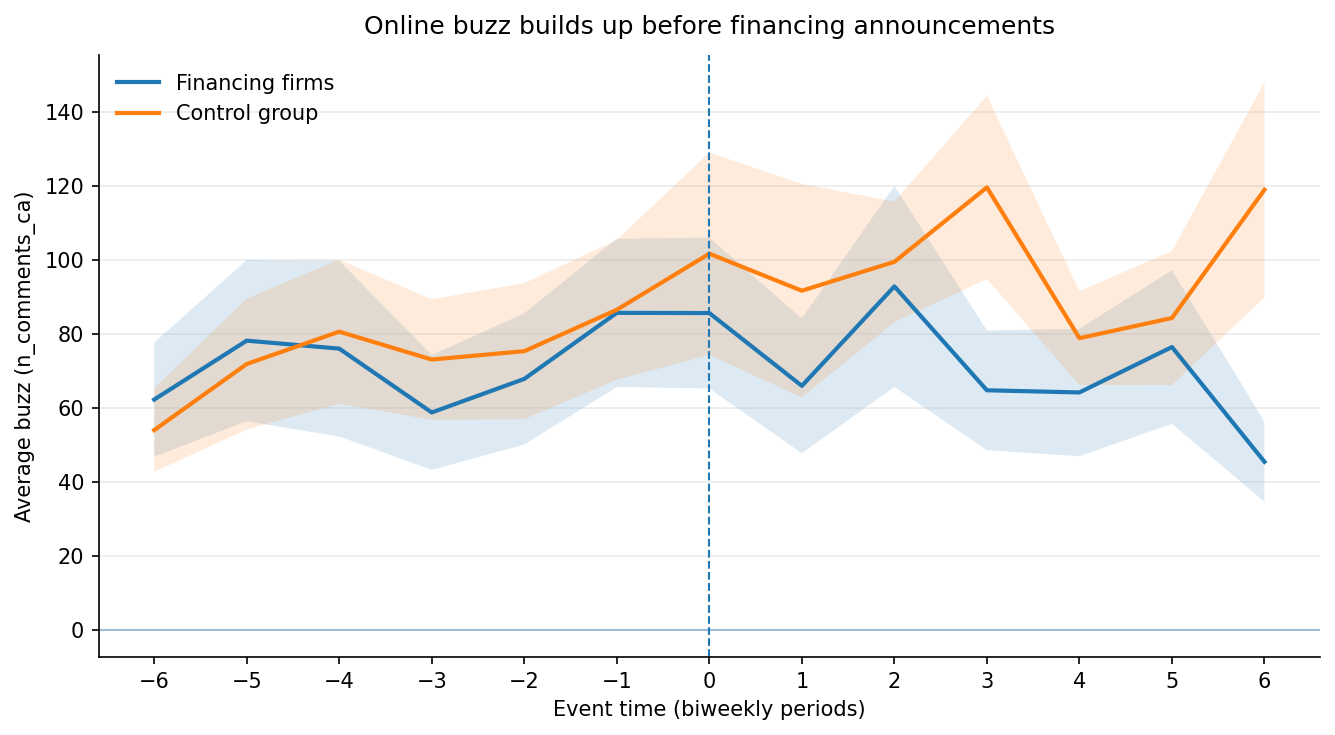

In [14]:
# ============================================================
# 5) PLOT — Buzz around financing events
# ============================================================
plot_df = (
    df_event_pd
    .groupby(["event_time", "is_financing_event"])
    .agg(
        mean_buzz=(METRIC, "mean"),
        std_buzz=(METRIC, "std"),
        n=(METRIC, "count")
    )
    .reset_index()
)

plot_df["se"] = plot_df["std_buzz"] / np.sqrt(plot_df["n"])
plot_df = plot_df.sort_values(["is_financing_event", "event_time"])

fin = plot_df[plot_df["is_financing_event"] == 1].sort_values("event_time")
nonfin = plot_df[plot_df["is_financing_event"] == 0].sort_values("event_time")

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

ax.plot(
    fin["event_time"],
    fin["mean_buzz"],
    linewidth=2,
    label="Financing firms"
)
ax.fill_between(
    fin["event_time"],
    fin["mean_buzz"] - fin["se"],
    fin["mean_buzz"] + fin["se"],
    alpha=0.15
)

ax.plot(
    nonfin["event_time"],
    nonfin["mean_buzz"],
    linewidth=2,
    label="Control group"
)
ax.fill_between(
    nonfin["event_time"],
    nonfin["mean_buzz"] - nonfin["se"],
    nonfin["mean_buzz"] + nonfin["se"],
    alpha=0.15
)

ax.axvline(0, linestyle="--", linewidth=1)
ax.axhline(0, linestyle="-", linewidth=1, alpha=0.4)

ax.set_title("Online buzz builds up before financing announcements", pad=10)
ax.set_xlabel("Event time (biweekly periods)")
ax.set_ylabel("Average buzz (n_comments_ca)")

xticks = sorted(df_event_pd["event_time"].unique())
ax.set_xticks(xticks)

ax.grid(True, which="major", axis="y", alpha=0.25)
ax.grid(False, axis="x")

ax.legend(frameon=False, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [15]:
print(METRIC)
df_event_pd[METRIC].describe()


n_comments_ca


count    685.000000
mean      78.829197
std      104.065481
min        1.000000
25%        8.000000
50%       44.000000
75%      105.000000
max      827.000000
Name: n_comments_ca, dtype: float64